### Project III

In [1]:
import pandas as pd
pd.set_option('display.max_columns', None), pd.set_option('display.max_rows', None)
import missingno as msno
from sklearn.preprocessing import  OrdinalEncoder
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import preprocessing
from sklearn import preprocessing
import plotly.graph_objects as plot
import plotly.graph_objects as plot
# import the KNNimputer class
from sklearn.impute import KNNImputer
import time

In [2]:
#Import dataset
data = pd.read_csv('fr_openfoodfacts_org_products.csv', sep = '\t')
data.columns = data.columns.str.replace('-', '_')
data.shape

/usr/local/lib/python3.6/site-packages/IPython/core/interactiveshell.py:3072: DtypeWarning:

Columns (0,3,5,19,20,24,25,26,27,28,35,36,37,38,39,48) have mixed types.Specify dtype option on import or set low_memory=False.



(320772, 162)

In [105]:
data.head(3)

,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,product_name,generic_name,quantity,packaging,packaging_tags,brands,brands_tags,categories,categories_tags,categories_fr,origins,origins_tags,manufacturing_places,manufacturing_places_tags,labels,labels_tags,labels_fr,emb_codes,emb_codes_tags,first_packaging_code_geo,cities,cities_tags,purchase_places,stores,countries,countries_tags,countries_fr,ingredients_text,allergens,allergens_fr,traces,traces_tags,traces_fr,serving_size,no_nutriments,additives_n,additives,additives_tags,additives_fr,ingredients_from_palm_oil_n,ingredients_from_palm_oil,ingredients_from_palm_oil_tags,ingredients_that_may_be_from_palm_oil_n,ingredients_that_may_be_from_palm_oil,ingredients_that_may_be_from_palm_oil_tags,nutrition_grade_uk,nutrition_grade_fr,pnns_groups_1,pnns_groups_2,states,states_tags,states_fr,main_category,main_category_fr,image_url,image_small_url,energy_100g,energy_from_fat_100g,fat_100g,saturated_fat_100g,butyric_acid_100g,caproic_acid_100g,caprylic_acid_100g,capric_acid_100g,lauric_acid_100g,myristic_acid_100g,palmitic_acid_100g,stearic_acid_100g,arachidic_acid_100g,behenic_acid_100g,lignoceric_acid_100g,cerotic_acid_100g,montanic_acid_100g,melissic_acid_100g,monounsaturated_fat_100g,polyunsaturated_fat_100g,omega_3_fat_100g,alpha_linolenic_acid_100g,eicosapentaenoic_acid_100g,docosahexaenoic_acid_100g,omega_6_fat_100g,linoleic_acid_100g,arachidonic_acid_100g,gamma_linolenic_acid_100g,dihomo_gamma_linolenic_acid_100g,omega_9_fat_100g,oleic_acid_100g,elaidic_acid_100g,gondoic_acid_100g,mead_acid_100g,erucic_acid_100g,nervonic_acid_100g,trans_fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,sucrose_100g,glucose_100g,fructose_100g,lactose_100g,maltose_100g,maltodextrins_100g,starch_100g,polyols_100g,fiber_100g,proteins_100g,casein_100g,serum_proteins_100g,nucleotides_100g,salt_100g,sodium_100g,alcohol_100g,vitamin_a_100g,beta_carotene_100g,vitamin_d_100g,vitamin_e_100g,vitamin_k_100g,vitamin_c_100g,vitamin_b1_100g,vitamin_b2_100g,vitamin_pp_100g,vitamin_b6_100g,vitamin_b9_100g,folates_100g,vitamin_b12_100g,biotin_100g,pantothenic_acid_100g,silica_100g,bicarbonate_100g,potassium_100g,chloride_100g,calcium_100g,phosphorus_100g,iron_100g,magnesium_100g,zinc_100g,copper_100g,manganese_100g,fluoride_100g,selenium_100g,chromium_100g,molybdenum_100g,iodine_100g,caffeine_100g,taurine_100g,ph_100g,fruits_vegetables_nuts_100g,collagen_meat_protein_ratio_100g,cocoa_100g,chlorophyl_100g,carbon_footprint_100g,nutrition_score_fr_100g,nutrition_score_uk_100g,glycemic_index_100g,water_hardness_100g
0,3087,http://world-fr.openfoodfacts.org/produit/0000...,openfoodfacts-contributors,1474103866,2016-09-17T09:17:46Z,1474103893,2016-09-17T09:18:13Z,Farine de blé noir,NaN,1kg,NaN,NaN,Ferme t'y R'nao,ferme-t-y-r-nao,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,en:FR,en:france,France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"en:to-be-completed, en:nutrition-facts-to-be-c...","en:to-be-completed,en:nutrition-facts-to-be-co...","A compléter,Informations nutritionnelles à com...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4530,http://world-fr.openfoodfacts.org/produit/0000...,usda-ndb-import,1489069957,2017-03-09T14:32:37Z,1489069957,2017-03-09T14:32:37Z,Banana Chips Sweetened (Whole),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,US,en:united-states,États-Unis,"Bananas, vegetable oil (coconut oil, corn oil ...",NaN,NaN,NaN,NaN,NaN,28 g (1 ONZ),NaN,0.0,[ bananas -> en:bananas ] [ vegetable-oil -

### Suppression des doublons

In [4]:
data2 = data.drop_duplicates('code')
data2.shape, data.shape

((320639, 162), (320772, 162))

In [107]:
#data2.columns.values

### Comme idée d'application, nous pensons à la création d'un score définissant le risque d'hyperglycémie lié à la consommotion d'un produit par agrégation des indicateurs clé de contenance de sucre et de matière grasse tels que : 
#### <br/> sugars_100g <br/> sucrose_100g <br/> glucose_100g <br/> fructose_100g <br/> lactose_100g <br/> maltose_100g <br/> maltodextrins_100g <br/> starch_100g <br/> polyols_100g <br/> fat_100g <br/> saturated-fat_100g <br/> butyric-acid_100g <br/> caproic-acid_100g


In [6]:
l = ['code', 'product_name','creator', 'quantity', 'sugars_100g','countries', 'cities','pnns_groups_1', 'sucrose_100g','glucose_100g','fructose_100g','lactose_100g','maltose_100g','maltodextrins_100g','starch_100g','polyols_100g','fat_100g','cholesterol_100g','saturated_fat_100g','butyric_acid_100g','caproic_acid_100g','nutrition_grade_fr', 'nutrition_score_fr_100g','energy_from_fat_100g']

### Taux de remplissage et suppression des variables & observations quasiment vides (%null >= 70)
#### 1-Taux de remplissage et suppression des variables quasiment vides

In [7]:
df = data[l]
df_null = pd.DataFrame(df.isna().sum()/len(df)*100, columns = ['_null'])
l_ = df_null[df_null._null < 80].index.tolist()

In [8]:
df = df[l_]
df.columns

Index(['code', 'product_name', 'creator', 'quantity', 'sugars_100g',
       'countries', 'pnns_groups_1', 'fat_100g', 'cholesterol_100g',
       'saturated_fat_100g', 'nutrition_grade_fr', 'nutrition_score_fr_100g'],
      dtype='object')

#### 2-Taux de remplissage et suppression des Observation quasiment vides

In [111]:
tab = []
for index in range(len(df.index)) : 
    tab_ = df.iloc[index].isna().sum()
    tab.append(tab_)
df['nb_miss'] = tab
df.sort_values('nb_miss', ascending = True, inplace = True)
df.head(2)

,code,product_name,creator,quantity,sugars_100g,countries,pnns_groups_1,fat_100g,cholesterol_100g,saturated_fat_100g,nutrition_grade_fr,nutrition_score_fr_100g,nb_miss
96017,78354719008,Vermont Sharp Cheddar Cheese,stephane,8 oz,0.0,United States,Milk and dairy products,32.1,0.107,21.4,d,16.0,0
278919,5411188100799,Postre de soja Vainilla,javichu,500 g (4 x 125 g),10.6,España,Sugary snacks,1.9,0.000,0.4,b,2.0,0


#### Checker les observations quasiment vides
#### Garder les observations telles que la variable sugar_100g est renseignées

In [9]:
df[~df.sugars_100g.isna()].shape, df.shape # Il n'y pas de lignes ayant au moins 10% de valeurs manquantes
df = df[~df.sugars_100g.isna() | ~df.product_name.isna()]
df.shape

(306071, 12)

#suppression des valeurs abérrantes

In [113]:
''' Detection '''
'''# IQR
for i in df[numerical_vars].columns.tolist() : 
    Q1 = np.percentile(df[i], 25, interpolation = 'midpoint')
    Q3 = np.percentile(df[i], 75,interpolation = 'midpoint')
    IQR = Q3 - Q1
    print("Old Shape: ", df.shape)
    upper = np.where(df[i] >= (Q3+1.5*IQR))
    lower = np.where(df[i] <= (Q1-1.5*IQR))
    df.drop(upper[0], inplace = True)
    df.drop(lower[0], inplace = True)
print("New Shape: ", df.shape)'''

'# IQR\nfor i in df[numerical_vars].columns.tolist() : \n    Q1 = np.percentile(df[i], 25, interpolation = \'midpoint\')\n    Q3 = np.percentile(df[i], 75,interpolation = \'midpoint\')\n    IQR = Q3 - Q1\n    print("Old Shape: ", df.shape)\n    upper = np.where(df[i] >= (Q3+1.5*IQR))\n    lower = np.where(df[i] <= (Q1-1.5*IQR))\n    df.drop(upper[0], inplace = True)\n    df.drop(lower[0], inplace = True)\nprint("New Shape: ", df.shape)'

In [114]:
df.drop('nb_miss', axis = 1, inplace = True)
numerical_vars = [x for x in df.columns if df[x].dtype != 'object']
categorial_vars = [x for x in  df.columns if df[x].dtype == 'object']

In [121]:
df[categorial_vars].columns.tolist()

['code',
 'product_name',
 'creator',
 'quantity',
 'countries',
 'pnns_groups_1',
 'nutrition_grade_fr']

### Suppression des valeurs abérrantes

In [10]:
df['test1'] = 'na'
def my_fun (col1, col2):
    df[col2]= np.where(((df[col1]>=0.0) & (df[col1]<=100.0)), 'ok', 'nok')
    return df
df1 = my_fun('sugars_100g','test1')
df1 = my_fun('fat_100g','test2')
df1 = my_fun('cholesterol_100g','test3')
df1 = my_fun('saturated_fat_100g','test4')
def my_fun(col1, col2):
    df[col2]= np.where((df[col1]>=-15) & (df[col1]<=40), 'ok', 'nok')
    return df
df1 = my_fun('nutrition_score_fr_100g', 'test5')
df1.head()

,code,product_name,creator,quantity,sugars_100g,countries,pnns_groups_1,fat_100g,cholesterol_100g,saturated_fat_100g,nutrition_grade_fr,nutrition_score_fr_100g,test1,test2,test3,test4,test5
0,3087,Farine de blé noir,openfoodfacts-contributors,1kg,NaN,en:FR,NaN,NaN,NaN,NaN,NaN,NaN,nok,nok,nok,nok,nok
1,4530,Banana Chips Sweetened (Whole),usda-ndb-import,NaN,14.29,US,NaN,28.57,0.018,28.57,d,14.0,ok,ok,ok,ok,ok
2,4559,Peanuts,usda-ndb-import,NaN,17.86,US,NaN,17.86,0.000,0.00,b,0.0,ok,ok,ok,ok,ok
3,16087,Organic Salted Nut Mix,usda-ndb-import,NaN,3.57,US,NaN,57.14,NaN,5.36,d,12.0,ok,ok,nok,ok,ok
4,16094,Organic Polenta,usda-ndb-import,NaN,NaN,US,NaN,1.43,NaN,NaN,NaN,NaN,nok,ok,nok,nok,nok


#### Traitement de la variable pnns_groups_1

In [11]:
#df['pnns_groups_1'] = df.pnns_groups_1.fillna(df.pnns_groups_1.mode())
df['pnns_groups_1'].fillna('unknown', inplace=True)
#df.loc[df.pnns_groups_1== nan, 'pnns_groups_1'] = 'unknown'
df.pnns_groups_1.unique()

array(['unknown', 'Fruits and vegetables', 'Sugary snacks',
       'Cereals and potatoes', 'Composite foods', 'Fish Meat Eggs',
       'Beverages', 'Fat and sauces', 'fruits-and-vegetables',
       'Milk and dairy products', 'Salty snacks', 'sugary-snacks',
       'cereals-and-potatoes', 'salty-snacks'], dtype=object)

In [13]:
df_clean = df1[(df1.test1 =='ok') & (df1.test2 == 'ok') & (df1.test3 == 'ok') & (df1.test4 == 'ok') & (df1.test5 == 'ok')]
df_clean.shape, df1.shape
df_clean.drop(['test1', 'test2', 'test3', 'test4', 'test5'], axis = 1, inplace = True)
df_clean.to_csv('df_clean.csv')
df_clean.shape

(137068, 12)

In [128]:
df2 = df_clean.copy()
df3 = df_clean.copy()
for i in df_clean[numerical_vars].columns.tolist() : 
    df2[i].fillna(int(df_clean[i].mean()), inplace=True)
df_na_mean = df2
for i in df_clean[numerical_vars].columns.tolist() : 
    df3[i].fillna(int(df_clean[i].median()), inplace=True)
df_na_median = df3
#df_na_median = df.fillna(df.median())

In [129]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer,KNNImputer
from sklearn.linear_model import BayesianRidge
imp = IterativeImputer(estimator=BayesianRidge())
test = df_clean[numerical_vars].values
df_na_knn = imp.fit_transform(test)
df_na_knn2 = pd.DataFrame(df_na_knn, columns = numerical_vars)
df_na_knn2.head()
#df_na_knn[numerical_vars].isna().sum()

,sugars_100g,fat_100g,cholesterol_100g,saturated_fat_100g,nutrition_score_fr_100g
0,0.00,32.100,0.10700,21.400,16.0
1,10.60,1.900,0.00000,0.400,2.0
2,3.33,43.300,0.00000,5.000,6.0
3,23.60,29.100,0.12700,19.100,19.0
4,5.00,0.833,0.00417,0.625,3.0


In [ ]:
df_clean.shape

### Tracé des distributions des variables suivant les trois méthodes d'imputation

<Figure size 720x288 with 0 Axes>

<Figure size 1440x1440 with 0 Axes>

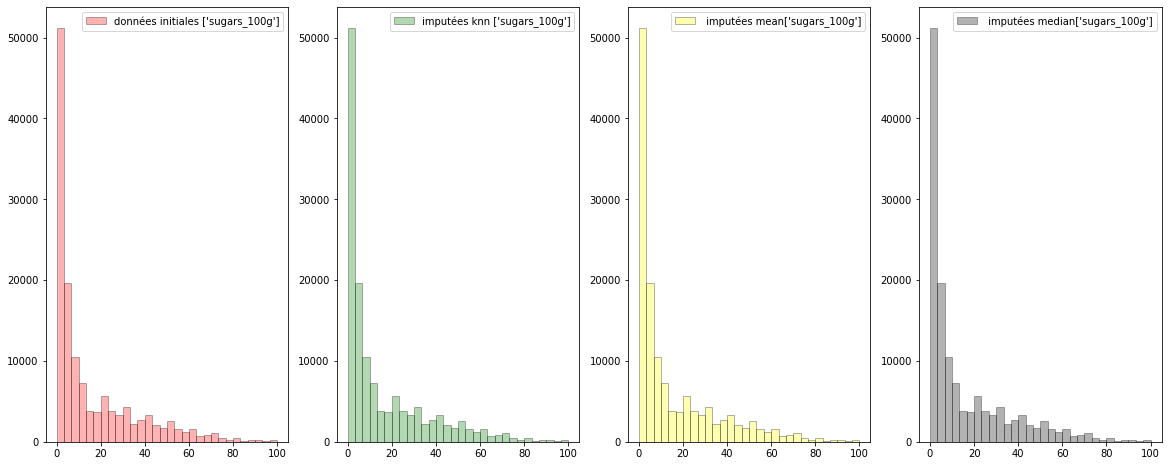

<Figure size 1440x1440 with 0 Axes>

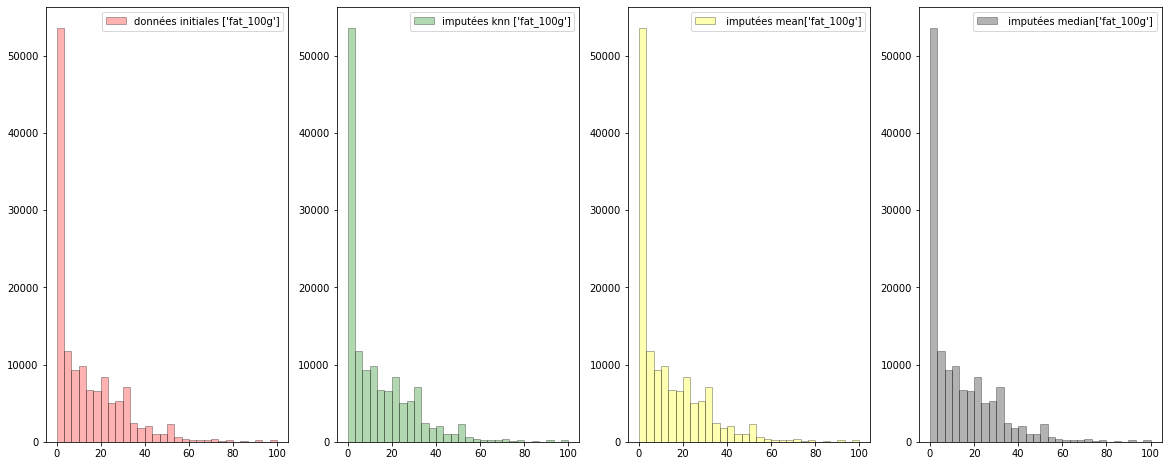

<Figure size 1440x1440 with 0 Axes>

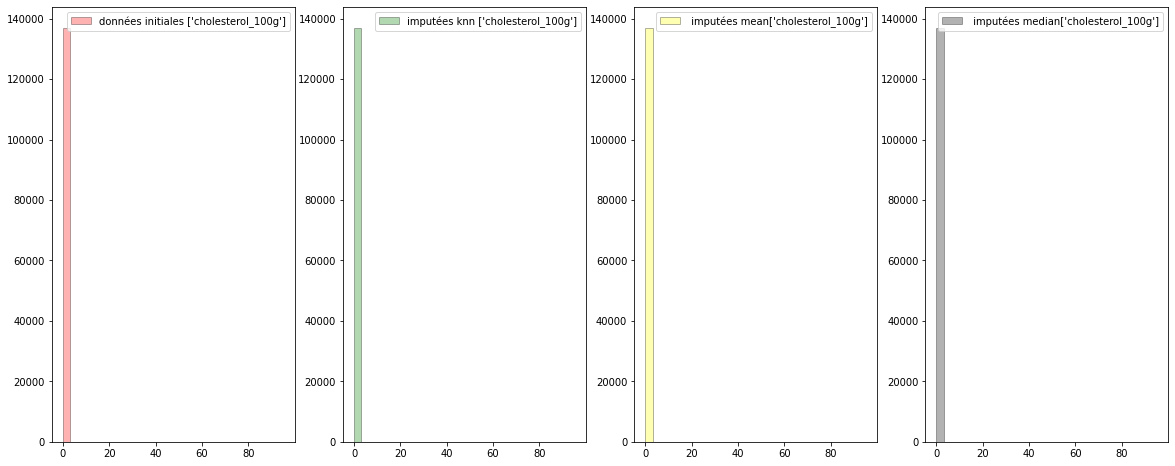

<Figure size 1440x1440 with 0 Axes>

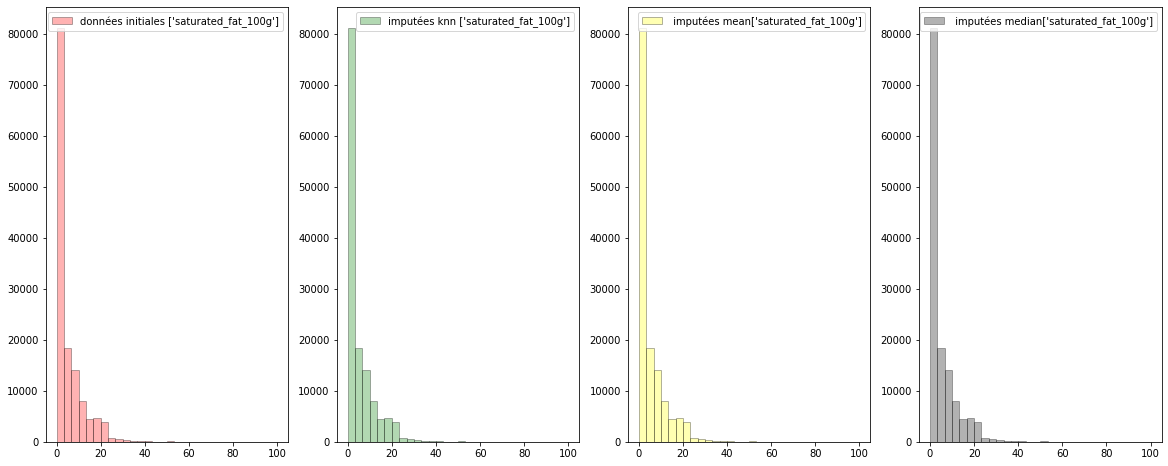

<Figure size 1440x1440 with 0 Axes>

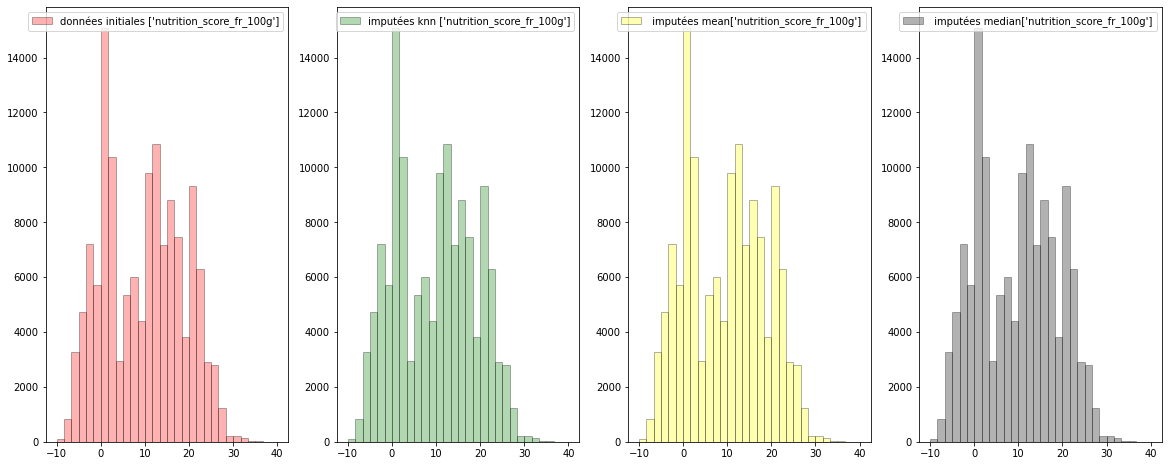

In [130]:
#n = df[numerical_vars].shape[1]
plt.figure(figsize=(10, 4))
for i in df_clean[numerical_vars].columns.tolist() :
    plt.figure(figsize=(20, 20))
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 8))
    ax1.hist(df_clean[numerical_vars][i], edgecolor='black', bins=30, alpha=.3, density=False, color='red', label=f'données initiales {[i]}') 
    ax2.hist(df_na_knn2[i], edgecolor='black', bins=30, alpha=.3, density=False, color='green', label=f'imputées knn {[i]}')
    ax3.hist(df_na_mean[numerical_vars][i], edgecolor='black', bins=30, alpha=.3, density=False, color='yellow', label=f' imputées mean{[i]}')
    ax4.hist(df_na_median[numerical_vars][i], edgecolor='black', bins=30, alpha=.3, density=False, color='black', label=f' imputées median{[i]}')
    for ax in fig.get_axes() : 
        ax.legend()
    plt.show()
    #ax.label_outer()